In [2]:
import pandas as pd

# 1. Membaca file CSV dari folder tempat ia berada
df = pd.read_csv("ecommerce_transaksi_dummy.csv")

# 2. Mengecek apakah ada kolom yang memiliki nilai kosong (NaN)
print("Jumlah data yang kosong di setiap kolom:")
print(df.isnull().sum())

Jumlah data yang kosong di setiap kolom:
id_transaksi           0
tanggal                0
id_pelanggan           0
nama_pelanggan         0
kategori_produk        0
nama_produk            0
harga_satuan           0
jumlah_beli            0
kota_pengiriman        0
status_pembayaran    258
dtype: int64


In [3]:
# Mengisi baris yang kosong (NaN) di kolom 'status_pembayaran' dengan teks "Tidak Diketahui"
df["status_pembayaran"] = df["status_pembayaran"].fillna("Tidak Diketahui")

# Cek kembali apakah masih ada yang kosong
print("Jumlah data kosong setelah dibersihkan:")
print(df.isnull().sum())

Jumlah data kosong setelah dibersihkan:
id_transaksi         0
tanggal              0
id_pelanggan         0
nama_pelanggan       0
kategori_produk      0
nama_produk          0
harga_satuan         0
jumlah_beli          0
kota_pengiriman      0
status_pembayaran    0
dtype: int64


In [4]:
# 1. Mengelompokkan berdasarkan 'kategori_produk' lalu menjumlahkan 'jumlah_beli'-nya
ringkasan_kategori = df.groupby("kategori_produk")["jumlah_beli"].sum()

# 2. Menampilkan hasilnya
print("Total Pembelian per Kategori Produk:")
print(ringkasan_kategori)

Total Pembelian per Kategori Produk:
kategori_produk
Elektronik           761
Makanan & Minuman    771
Pakaian              739
Rumah Tangga         768
Name: jumlah_beli, dtype: int64


In [5]:
# 1. Mengelompokkan, menjumlahkan, lalu mengurutkan dari yang terbesar ke terkecil
ringkasan_kategori = df.groupby("kategori_produk")["jumlah_beli"].sum().reset_index()

# 2. Mengurutkan berdasarkan kolom 'jumlah_beli' secara menurun (descending)
ringkasan_terurut = ringkasan_kategori.sort_values(by="jumlah_beli", ascending=False)

# 3. Menampilkan hasil
print(ringkasan_terurut)

     kategori_produk  jumlah_beli
1  Makanan & Minuman          771
3       Rumah Tangga          768
0         Elektronik          761
2            Pakaian          739


In [6]:
ringkasan_terurut = df.groupby("kategori_produk")["jumlah_beli"].sum().reset_index(drop=True)

In [7]:
print(ringkasan_terurut.to_string(index=False))

761
771
739
768


In [8]:
# 1. Membuat kolom baru: total pendapatan per baris transaksi
df["total_pendapatan"] = df["harga_satuan"] * df["jumlah_beli"]

# 2. Mengelompokkan total pendapatan berdasarkan kategori produk dan diurutkan
pendapatan_kategori = df.groupby("kategori_produk")["total_pendapatan"].sum().reset_index()
pendapatan_terurut = pendapatan_kategori.sort_values(by="total_pendapatan", ascending=False)

# 3. Menampilkan hasil dengan rapi tanpa angka indeks
print(pendapatan_terurut.to_string(index=False))

  kategori_produk  total_pendapatan
       Elektronik        2296650000
     Rumah Tangga         319100000
          Pakaian         143400000
Makanan & Minuman          46915000


In [9]:
# 1. Memastikan kolom tanggal terbaca sebagai format datetime
df["tanggal"] = pd.to_datetime(df["tanggal"])

# 2. Membuat kolom baru khusus untuk mengambil tahun-bulan (contoh: 2024-05)
df["bulan"] = df["tanggal"].dt.to_period("M")

# 3. Menghitung total pendapatan berdasarkan bulan
tren_bulanan = df.groupby("bulan")["total_pendapatan"].sum().reset_index()

# 4. Menampilkan hasil tren bulanan
print(tren_bulanan.to_string(index=False))

  bulan  total_pendapatan
2024-01         150915000
2024-02          83335000
2024-03          85455000
2024-04          65360000
2024-05          34290000
2024-06          46475000
2024-07          53500000
2024-08         170335000
2024-09         222365000
2024-10          74130000
2024-11         103455000
2024-12         148160000
2025-01          81515000
2025-02          93565000
2025-03         126215000
2025-04         107925000
2025-05         120075000
2025-06         115050000
2025-07         112085000
2025-08         127245000
2025-09          59915000
2025-10          49255000
2025-11         203310000
2025-12         110245000
2026-01         136800000
2026-02         104515000
2026-03          20575000


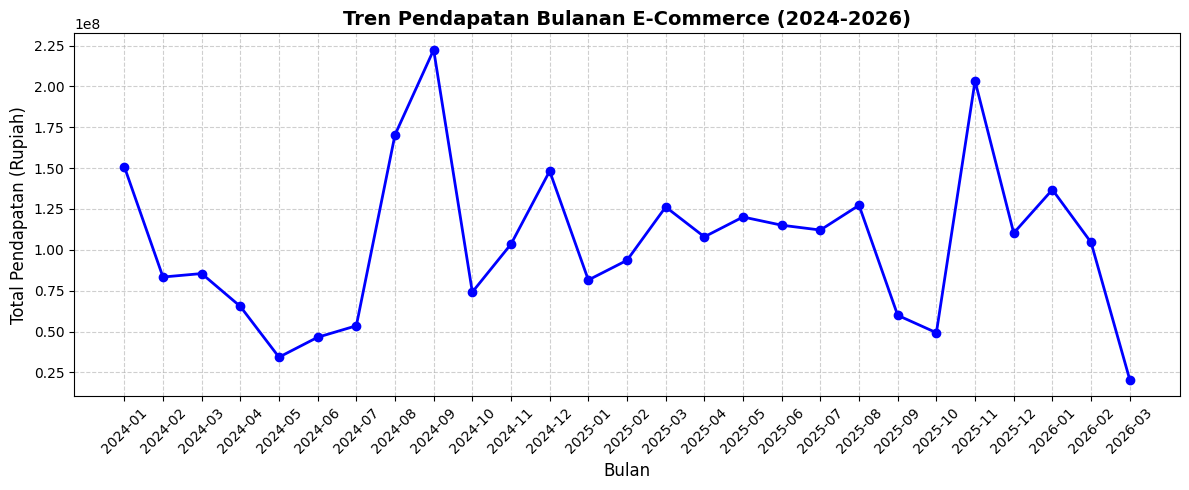

In [10]:
import matplotlib.pyplot as plt

# 1. Mengubah kolom periode bulan menjadi string agar mudah dibaca di sumbu X
tren_bulanan["bulan_str"] = tren_bulanan["bulan"].astype(str)

# 2. Mengatur ukuran kanvas gambar
plt.figure(figsize=(12, 5))

# 3. Membuat Line Chart (Grafik Garis)
plt.plot(tren_bulanan["bulan_str"], tren_bulanan["total_pendapatan"], marker='o', color='blue', linewidth=2)

# 4. Memberikan judul dan label agar profesional
plt.title("Tren Pendapatan Bulanan E-Commerce (2024-2026)", fontsize=14, fontweight='bold')
plt.xlabel("Bulan", fontsize=12)
plt.ylabel("Total Pendapatan (Rupiah)", fontsize=12)

# Memutar label tanggal di bawah agar tidak saling bertumpuk
plt.xticks(rotation=45)

# Menambahkan garis grid tipis agar mudah dibaca nilainya
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# 5. Menampilkan grafik
plt.show()

In [11]:
# 1. Mengelompokkan berdasarkan nama pelanggan dan menjumlahkan total pendapatan mereka
top_pelanggan = df.groupby("nama_pelanggan")["total_pendapatan"].sum().reset_index()

# 2. Mengurutkan dari pendapatan terbesar ke terkecil
top_pelanggan_terurut = top_pelanggan.sort_values(by="total_pendapatan", ascending=False)

# 3. Menampilkan 5 pelanggan teratas teratas tanpa indeks
print("=== 5 PELANGGAN TERATAS (TOP SPENDER) ===")
print(top_pelanggan_terurut.head(5).to_string(index=False))

=== 5 PELANGGAN TERATAS (TOP SPENDER) ===
nama_pelanggan  total_pendapatan
         Rizki         427290000
          Rina         326280000
         Putri         250755000
          Dewi         239300000
         Ahmad         238845000


In [12]:
import datetime as dt

# 1. Tentukan tanggal acuan (Snapshot Date) 1 hari setelah transaksi paling akhir
tanggal_acuan = df["tanggal"].max() + dt.timedelta(days=1)

# 2. Menghitung nilai Recency, Frequency, dan Monetary
df_rfm = df.groupby("nama_pelanggan").agg({
    'tanggal': lambda x: (tanggal_acuan - x.max()).days, # Recency (selisih hari)
    'id_transaksi': 'count',                             # Frequency (jumlah transaksi)
    'total_pendapatan': 'sum'                            # Monetary (total rupiah)
}).reset_index()

# 3. Merapikan nama kolom
df_rfm.columns = ['nama_pelanggan', 'Recency', 'Frequency', 'Monetary']

# 4. Tampilkan 5 pelanggan teratas berdasarkan Monetary
print("=== HASIL PERHITUNGAN RFM PELANGGAN ===")
print(df_rfm.sort_values(by="Monetary", ascending=False).head(5).to_string(index=False))

=== HASIL PERHITUNGAN RFM PELANGGAN ===
nama_pelanggan  Recency  Frequency  Monetary
         Rizki        6         88 427290000
          Rina        9         83 326280000
         Putri        7         86 250755000
          Dewi        4         85 239300000
         Ahmad       16        102 238845000


In [13]:
# Fungsi sederhana untuk menentukan segmen pelanggan
def beri_segmen(row):
    if row['Monetary'] >= 300000000:
        return 'Champions / VIP'
    elif row['Frequency'] >= 5:
        return 'Loyal Customers'
    elif row['Recency'] <= 30:
        return 'Recent Customers'
    else:
        return 'Regular Customers'

# Menerapkan fungsi ke setiap baris
df_rfm['Segmen'] = df_rfm.apply(beri_segmen, axis=1)

# Menampilkan distribusi jumlah pelanggan di setiap segmen
print("=== DISTRIBUSI SEGMEN PELANGGAN ===")
print(df_rfm['Segmen'].value_counts())

=== DISTRIBUSI SEGMEN PELANGGAN ===
Segmen
Loyal Customers    10
Champions / VIP     2
Name: count, dtype: int64
